In [ ]:
!pip install -q scikit-image

import os
import shutil
import cv2
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from skimage.metrics import peak_signal_noise_ratio as psnr
from skimage.metrics import structural_similarity as ssim

VALID_EXT = {'.jpg', '.jpeg', '.png', '.bmp', '.tif', '.tiff', '.webp'}

INPUT_DIR  = '/content/input'
OUTPUT_DIR = '/content/output'
os.makedirs(INPUT_DIR, exist_ok=True)
os.makedirs(OUTPUT_DIR, exist_ok=True)

def imread_rgb(path):
    img = cv2.imread(str(path), cv2.IMREAD_COLOR)
    if img is None:
        raise FileNotFoundError(f'Could not read image: {path}')
    return cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

def imwrite_rgb(path, img_rgb):
    bgr = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2BGR)
    cv2.imwrite(str(path), bgr)

def show(images, titles=None, cols=3, figsize_scale=4):
    # Display a list of RGB images in a grid.
    n = len(images)
    rows = (n + cols - 1) // cols
    plt.figure(figsize=(figsize_scale * cols, figsize_scale * rows))
    for i, img in enumerate(images):
        plt.subplot(rows, cols, i + 1)
        cmap = 'gray' if img.ndim == 2 else None
        plt.imshow(img, cmap=cmap)
        plt.axis('off')
        if titles:
            plt.title(titles[i], fontsize=11)
    plt.tight_layout()
    plt.show()


In [ ]:
from google.colab import files

uploaded = files.upload()

saved = []
for fname, content in uploaded.items():
    dest = os.path.join(INPUT_DIR, fname)
    with open(dest, 'wb') as f:
        f.write(content)
    saved.append(fname)

print(f'Saved {len(saved)} file(s) to {INPUT_DIR}:')
for f in saved:
    print(' -', f)


Saving pexels-shukur-18324265_noisy.jpg to pexels-shukur-18324265_noisy.jpg
Saving pexels-sevde-altintas-2163334077-39419712_low_contrast.jpg to pexels-sevde-altintas-2163334077-39419712_low_contrast.jpg
Saving pexels-sevde-altintas-2163334077-39419712_noisy.jpg to pexels-sevde-altintas-2163334077-39419712_noisy.jpg
Saving pexels-shukur-18324265_blurred.jpg to pexels-shukur-18324265_blurred.jpg
Saving pexels-shukur-18324265_bright.jpg to pexels-shukur-18324265_bright.jpg
Saving pexels-shukur-18324265_clean.jpg to pexels-shukur-18324265_clean.jpg
Saving pexels-shukur-18324265_dark.jpg to pexels-shukur-18324265_dark.jpg
Saving pexels-shukur-18324265_low_contrast.jpg to pexels-shukur-18324265_low_contrast.jpg
Saving pexels-nur-cosar-2152749774-35348502_noisy.jpg to pexels-nur-cosar-2152749774-35348502_noisy.jpg
Saving pexels-sevde-altintas-2163334077-39419712_blurred.jpg to pexels-sevde-altintas-2163334077-39419712_blurred.jpg
Saving pexels-sevde-altintas-2163334077-39419712_bright.jpg to

In [ ]:
def analyze_quality(img_rgb):

    gray = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2GRAY)

    brightness = float(np.mean(gray))
    contrast   = float(np.std(gray))
    blur_score = float(cv2.Laplacian(gray, cv2.CV_64F).var())
    denoised_ref = cv2.GaussianBlur(gray, (5, 5), 0)
    noise_score = float(np.mean(np.abs(gray.astype(np.float32) - denoised_ref.astype(np.float32))))

    clipped_dark  = float(np.mean(gray < 8))
    clipped_bright = float(np.mean(gray > 247))

    return {
        'brightness': brightness,
        'contrast': contrast,
        'blur_score': blur_score,
        'noise_score': noise_score,
        'clipped_dark_pct': clipped_dark * 100,
        'clipped_bright_pct': clipped_bright * 100,
    }

def describe_quality(metrics):

    tags = []
    if metrics['brightness'] < 90:
        tags.append('dark / underexposed')
    if metrics['brightness'] > 175:
        tags.append('bright / overexposed')
    if metrics['contrast'] < 40:
        tags.append('low contrast')
    if metrics['blur_score'] < 100:
        tags.append('blurred')
    if metrics['noise_score'] > 6:
        tags.append('noisy')
    if not tags:
        tags.append('no major defects detected')
    return tags


In [ ]:
def apply_gamma_correction(img_rgb, gamma=None, target_mean=130.0):

    gray_mean = np.mean(cv2.cvtColor(img_rgb, cv2.COLOR_RGB2GRAY))
    if gamma is None:
        gray_mean = max(gray_mean, 1e-3)
        gamma = np.log(target_mean / 255.0) / np.log(gray_mean / 255.0)
        gamma = float(np.clip(gamma, 0.3, 3.0))
    inv_gamma = 1.0 / gamma
    table = np.array([((i / 255.0) ** inv_gamma) * 255 for i in range(256)]).astype('uint8')
    return cv2.LUT(img_rgb, table), gamma


def apply_clahe(img_rgb, clip_limit=2.5, tile_grid_size=(8, 8)):

    lab = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2LAB)
    l, a, b = cv2.split(lab)
    clahe = cv2.createCLAHE(clipLimit=clip_limit, tileGridSize=tile_grid_size)
    l_eq = clahe.apply(l)
    merged = cv2.merge((l_eq, a, b))
    return cv2.cvtColor(merged, cv2.COLOR_LAB2RGB)


def apply_histogram_equalization(img_rgb):
    ycrcb = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2YCrCb)
    y, cr, cb = cv2.split(ycrcb)
    y_eq = cv2.equalizeHist(y)
    merged = cv2.merge((y_eq, cr, cb))
    return cv2.cvtColor(merged, cv2.COLOR_YCrCb2RGB)


def apply_contrast_stretch(img_rgb, low_pct=2, high_pct=98):
    out = np.zeros_like(img_rgb)
    for c in range(3):
        channel = img_rgb[:, :, c].astype(np.float32)
        lo, hi = np.percentile(channel, [low_pct, high_pct])
        if hi - lo < 1e-3:
            out[:, :, c] = img_rgb[:, :, c]
            continue
        stretched = (channel - lo) * 255.0 / (hi - lo)
        out[:, :, c] = np.clip(stretched, 0, 255)
    return out.astype('uint8')


def apply_unsharp_mask(img_rgb, sigma=1.5, strength=1.5):
    blurred = cv2.GaussianBlur(img_rgb, (0, 0), sigma)
    sharpened = cv2.addWeighted(img_rgb, 1 + strength, blurred, -strength, 0)
    return np.clip(sharpened, 0, 255).astype('uint8')


def apply_denoise(img_rgb, strength=10):
    return cv2.fastNlMeansDenoisingColored(img_rgb, None, strength, strength, 7, 21)


def apply_white_balance(img_rgb):
    result = img_rgb.astype(np.float32)
    avg = result.reshape(-1, 3).mean(axis=0)
    gray_avg = avg.mean()
    scale = gray_avg / (avg + 1e-6)
    result = result * scale
    return np.clip(result, 0, 255).astype('uint8')


In [ ]:
def auto_enhance(img_rgb, verbose=True):
    metrics = analyze_quality(img_rgb)
    defects = describe_quality(metrics)
    if verbose:
        print('Detected:', ', '.join(defects))
        print({k: round(v, 2) for k, v in metrics.items()})

    out = img_rgb.copy()

    if metrics['noise_score'] > 6:
        out = apply_denoise(out, strength=8)

    out = apply_white_balance(out)

    if metrics['brightness'] < 90 or metrics['brightness'] > 175:
        out, gamma_used = apply_gamma_correction(out)
        if verbose:
            print(f'Applied gamma correction (gamma={gamma_used:.2f})')

    if metrics['contrast'] < 40:
        out = apply_clahe(out, clip_limit=3.0)
        if verbose:
            print('Applied CLAHE for low contrast')

    if metrics['blur_score'] < 100:
        out = apply_unsharp_mask(out, sigma=1.2, strength=1.2)
        if verbose:
            print('Applied unsharp masking for blur')

    return out, metrics


Detected: low contrast, blurred
{'brightness': 172.72, 'contrast': 39.11, 'blur_score': 1.0, 'noise_score': 0.06, 'clipped_dark_pct': 0.0, 'clipped_bright_pct': 0.0}
Applied CLAHE for low contrast
Applied unsharp masking for blur


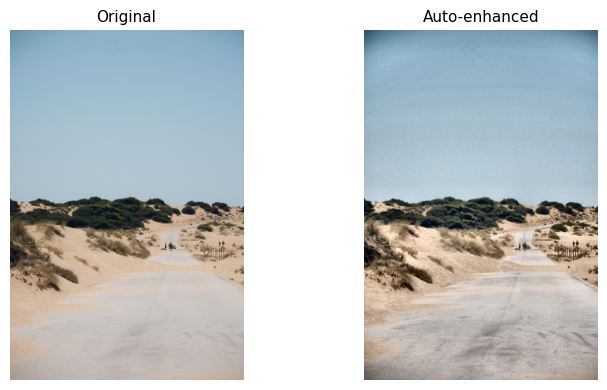

In [ ]:
up_files = sorted([f for f in os.listdir(INPUT_DIR) if Path(f).suffix.lower() in VALID_EXT])
assert up_files, f'No images found in {INPUT_DIR}. Run the upload cell (Section 2) first.'

sample_path = os.path.join(INPUT_DIR, up_files[0])
original = imread_rgb(sample_path)
enhanced, metrics = auto_enhance(original)

show([original, enhanced], titles=['Original', 'Auto-enhanced'], cols=2)


In [ ]:
results_log = []

for fname in up_files:
    in_path = os.path.join(INPUT_DIR, fname)
    out_path = os.path.join(OUTPUT_DIR, fname)

    img = imread_rgb(in_path)
    enhanced, metrics = auto_enhance(img, verbose=False)
    imwrite_rgb(out_path, enhanced)

    before = analyze_quality(img)
    after = analyze_quality(enhanced)
    results_log.append({'file': fname, 'defects': describe_quality(before),
                         'before': before, 'after': after})

    print(f'{fname:30s} -> defects: {", ".join(describe_quality(before))}')

print(f'\nDone. {len(up_files)} image(s) saved to {OUTPUT_DIR}')


pexels-alinson-torres-2157639132-39315274_blurred.jpg -> defects: low contrast, blurred
pexels-alinson-torres-2157639132-39315274_bright.jpg -> defects: bright / overexposed, low contrast, blurred
pexels-alinson-torres-2157639132-39315274_clean.jpg -> defects: low contrast, blurred
pexels-alinson-torres-2157639132-39315274_dark.jpg -> defects: dark / underexposed, low contrast, blurred
pexels-alinson-torres-2157639132-39315274_low_contrast.jpg -> defects: low contrast, blurred
pexels-alinson-torres-2157639132-39315274_noisy.jpg -> defects: noisy
pexels-axp-photography-500641970-19227922_blurred.jpg -> defects: blurred
pexels-axp-photography-500641970-19227922_bright.jpg -> defects: bright / overexposed, noisy
pexels-axp-photography-500641970-19227922_clean.jpg -> defects: noisy
pexels-axp-photography-500641970-19227922_dark.jpg -> defects: dark / underexposed, low contrast
pexels-axp-photography-500641970-19227922_low_contrast.jpg -> defects: low contrast
pexels-axp-photography-5006419

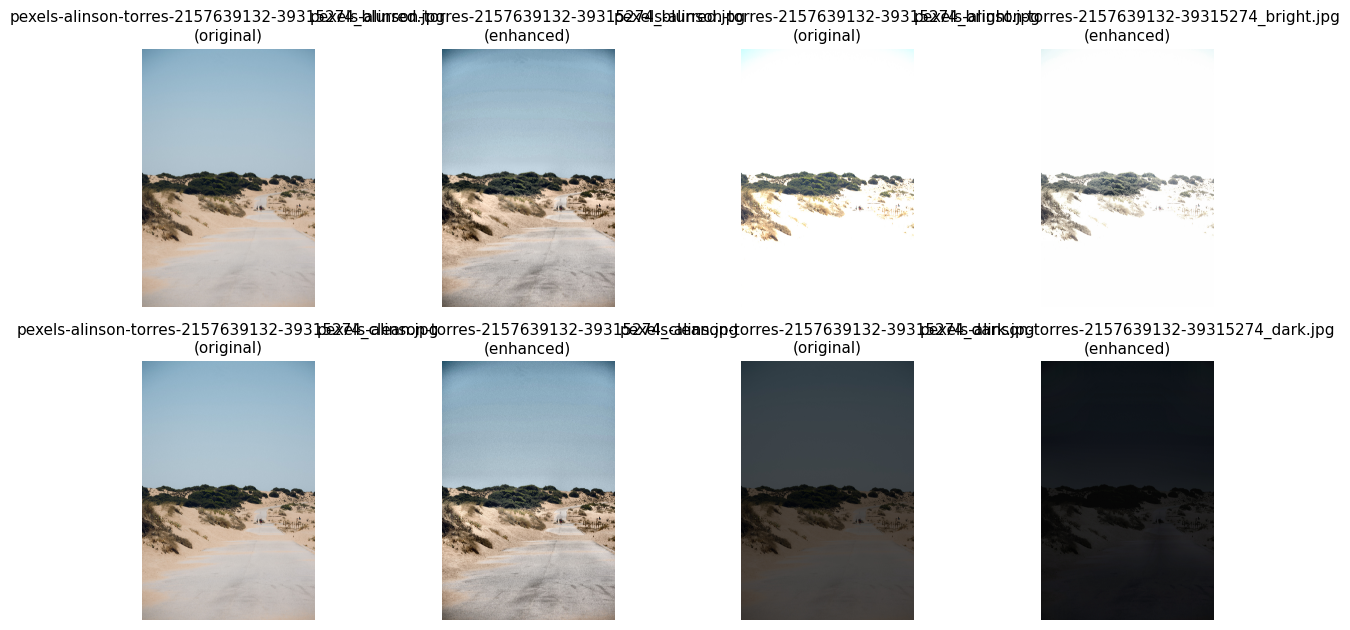

In [ ]:
preview_n = min(4, len(up_files))
imgs, titles = [], []
for fname in up_files[:preview_n]:
    orig = imread_rgb(os.path.join(INPUT_DIR, fname))
    enh  = imread_rgb(os.path.join(OUTPUT_DIR, fname))
    imgs += [orig, enh]
    titles += [f'{fname}\n(original)', f'{fname}\n(enhanced)']

show(imgs, titles=titles, cols=4, figsize_scale=3.2)
